# 05 — Interprétabilité du modèle retenu (SHAP)
**Projet : Détection de fraude financière — IEEE-CIS Fraud Detection**

Ce notebook couvre le **Chapitre 10**. Il s'applique **uniquement au modèle retenu** au chapitre 9 (`outputs/best_model.json`) et répond à deux questions :
- **Globale** : quelles variables influencent le plus les décisions du modèle, et dans quel sens ?
- **Locale** : pourquoi une transaction précise a-t-elle été classée *fraude* (ou, au contraire, manquée) ?

**Méthode.** Les valeurs de **SHAP** (SHapley Additive exPlanations) décomposent la prédiction d'une transaction en une valeur de base (prédiction moyenne) plus la contribution de chaque variable. Pour un modèle d'arbres, `TreeExplainer` calcule ces contributions de manière exacte et rapide ; pour une régression logistique, `LinearExplainer`. Pour XGBoost et la régression logistique, les contributions sont exprimées en **log-odds** (échelle du score avant transformation en probabilité) et, pour le Random Forest, en probabilité : une valeur positive pousse vers *fraude*, une valeur négative vers *légitime*.

**Visualisations** : importance des variables (native), SHAP Summary Plot, SHAP Bar Plot, SHAP Waterfall Plot, SHAP Force Plot.

> **Note de lecture.** Les cellules Markdown d'interprétation décrivent la lecture des graphiques et les enseignements habituels sur ce jeu de données. Les variables et valeurs exactes sont celles affichées par les cellules de code ; elles doivent être citées dans le mémoire après exécution.

## 10.0 Initialisation et chargement du modèle retenu

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})

SEED = 42
N_SHAP = 5000        # nombre de transactions du test expliquées (réduire si le calcul est trop long)
ROOT = Path("..").resolve()
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

retenu = json.load(open(ROOT / "outputs" / "best_model.json", encoding="utf-8"))
nom_modele, seuil = retenu["nom"], retenu["seuil_optimal"]
modele = joblib.load(ROOT / retenu["fichier_modele"])
print(f"Modèle retenu : {nom_modele} | seuil de décision : {seuil:.4f}")

test = pd.read_parquet(ROOT / "data" / "processed" / "test.parquet")
X_test, y_test = test.drop(columns="isFraud"), test["isFraud"]
proba_test = modele.predict_proba(X_test)[:, 1]
print(f"Jeu de test : {X_test.shape} | fraudes : {int(y_test.sum()):,}")

# La régression logistique est un Pipeline (StandardScaler + modèle) : on isole l'estimateur final
estimateur = modele[-1] if nom_modele == "Régression Logistique" else modele

Modèle retenu : XGBoost | seuil de décision : 0.5781
Jeu de test : (88581, 172) | fraudes : 3,099


### Interprétation — Chargement

**Résultat.** Le modèle retenu est chargé avec son seuil de décision optimal, ainsi que le jeu de test intact : l'interprétation porte sur des données que le modèle n'a jamais vues à l'entraînement.

**Points forts.** L'analyse reflète le comportement réel du modèle en généralisation, et non sa mémorisation du jeu d'apprentissage.

**Limites.** SHAP explique le **modèle**, pas la réalité : une variable influente est un indice de ce que le modèle exploite, non une cause de la fraude.

## 10.1 Importance des variables (native)

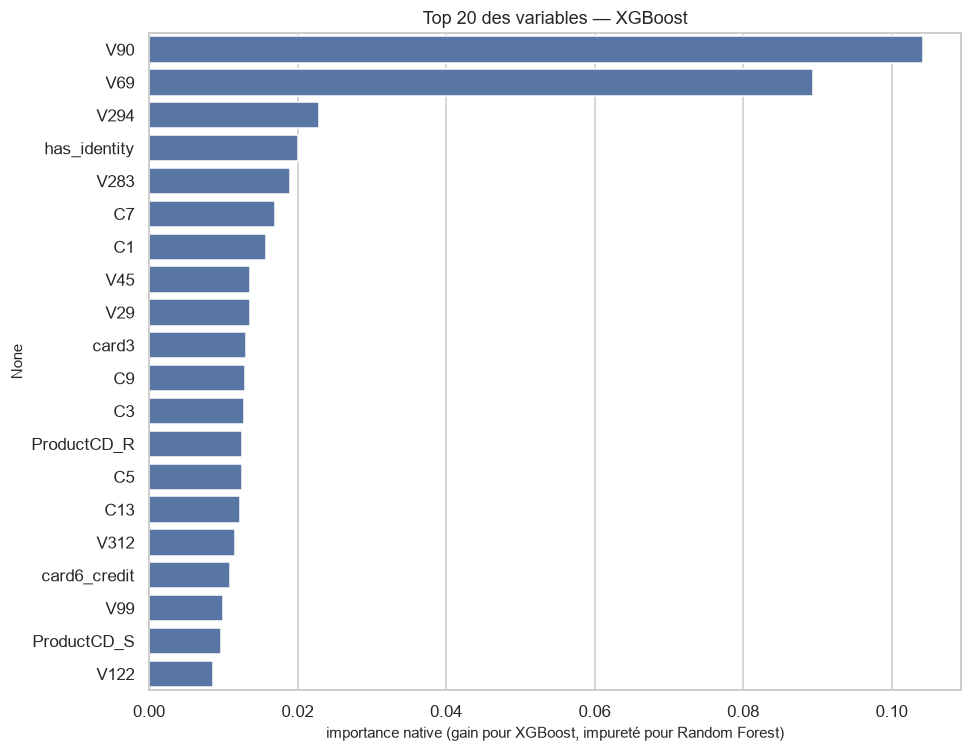

,importance
V90,0.1042
V69,0.0894
V294,0.0229
has_identity,0.0201
V283,0.0190
C7,0.0170
C1,0.0157
V45,0.0136
V29,0.0135
card3,0.0131


In [2]:
# Régression logistique : |coefficient| (variables standardisées) ; arbres : importance native du modèle
if nom_modele == "Régression Logistique":
    importance = pd.Series(np.abs(estimateur.coef_[0]), index=X_test.columns)
    type_importance = "|coefficient| (variables standardisées)"
else:
    importance = pd.Series(estimateur.feature_importances_, index=X_test.columns)
    type_importance = "importance native (gain pour XGBoost, impureté pour Random Forest)"

top20 = importance.sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x=top20.values, y=top20.index, color="#4C72B0", ax=ax)
ax.set_title(f"Top 20 des variables — {nom_modele}")
ax.set_xlabel(type_importance)
plt.tight_layout()
plt.savefig(FIG / "05_feature_importance.png", dpi=150)
plt.show()
top20.to_frame("importance")

### Interprétation — Importance des variables

**Résultat.** Le graphique classe les 20 variables les plus utilisées par le modèle. Sur IEEE-CIS, on retrouve typiquement des variables de comptage (`C*`), de délai (`D*`), des attributs de carte et d'adresse (`card*`, `addr1`), le montant, ainsi que des indicateurs liés au produit, à l'appareil et à la présence d'identité (`ProductCD_*`, `DeviceType_*`, `has_identity`). La confirmation vient des valeurs affichées.

**Points forts.** Lecture immédiate et gratuite : aucun calcul supplémentaire par rapport à l'entraînement.

**Limites.**
- L'importance **native** est globale et **sans signe** : elle ne dit pas si une variable augmente ou diminue le risque.
- Elle est biaisée en faveur des variables à nombreuses valeurs distinctes (`card1`, `addr1`, montants) et se répartit arbitrairement entre variables corrélées.
- Elle dépend de la définition utilisée (gain, nombre de splits, impureté). C'est pourquoi on la complète par SHAP, plus cohérent et plus riche.

## 10.2 Calcul des valeurs SHAP

Le calcul est réalisé sur un **échantillon aléatoire de transactions du jeu de test**, complété par trois cas choisis pour l'interprétation locale :
- une **fraude détectée** (vrai positif) avec une probabilité élevée ;
- une **fraude manquée** (faux négatif), la plus proche du seuil — le cas le plus instructif pour un métier qui cherche à minimiser les faux négatifs ;
- une **transaction légitime** correctement classée (vrai négatif) à faible probabilité.

In [3]:
pred_test = proba_test >= seuil
y_arr = y_test.values

# Cas d'étude (positions dans X_test) ; repli sur un cas voisin si une catégorie est vide
pos_tp = int(np.argmax(np.where((y_arr == 1) & pred_test, proba_test, -1)))
pos_fn = int(np.argmax(np.where((y_arr == 1) & ~pred_test, proba_test, -1))) if ((y_arr == 1) & ~pred_test).any() else None
pos_tn = int(np.argmin(np.where((y_arr == 0) & ~pred_test, proba_test, 2)))
exemples = {"Fraude détectée (vrai positif)": X_test.index[pos_tp], "Transaction légitime (vrai négatif)": X_test.index[pos_tn]}
if pos_fn is not None:
    exemples["Fraude manquée (faux négatif)"] = X_test.index[pos_fn]

echantillon = X_test.sample(min(N_SHAP, len(X_test)), random_state=SEED)
X_shap = X_test.loc[sorted(set(echantillon.index) | set(exemples.values()))]
print(f"{len(X_shap):,} transactions expliquées dont {len(exemples)} cas d'étude")

if nom_modele == "Régression Logistique":
    scaler = modele[0]
    fond = pd.DataFrame(scaler.transform(X_test.sample(1000, random_state=SEED)), columns=X_test.columns)
    explainer = shap.LinearExplainer(estimateur, fond)
    X_scaled = pd.DataFrame(scaler.transform(X_shap), columns=X_shap.columns, index=X_shap.index)
    sv = explainer(X_scaled)
    sv.data = X_shap.values                      # valeurs d'origine pour l'affichage
else:
    explainer = shap.TreeExplainer(estimateur)
    sv = explainer(X_shap, check_additivity=False)
    if sv.values.ndim == 3:                      # Random Forest : une sortie par classe -> classe 1 (fraude)
        sv = sv[:, :, 1]

print("Matrice SHAP :", sv.values.shape)
print("Valeur de base (prédiction moyenne) :", float(np.mean(sv.base_values)))

5,002 transactions expliquées dont 3 cas d'étude
Matrice SHAP : (5002, 172)
Valeur de base (prédiction moyenne) : 0.3213336765766144


### Interprétation — Calcul SHAP

**Résultat.** On obtient une matrice transactions × variables : chaque cellule est la contribution de la variable à la prédiction de la transaction. Pour toute transaction, `valeur de base + somme des contributions = score du modèle` (propriété d'additivité).

**Points forts.** L'explication est exacte pour les arbres (`TreeExplainer`), cohérente (une variable qui contribue davantage reçoit une valeur SHAP plus grande) et à la fois **globale** et **locale**.

**Limites.**
- Le calcul est fait sur un échantillon (résultats globaux stables dès quelques milliers de lignes, mais approximatifs).
- Les variables **corrélées** se partagent le crédit : l'importance d'une variable peut être sous-estimée si une proche corrélée la remplace.
- Les contributions sont exprimées en **log-odds** (XGBoost) : la valeur de base est élevée à cause de `scale_pos_weight`, qui déforme l'échelle des scores sans changer le classement des transactions.

## 10.3 SHAP Summary Plot (beeswarm)

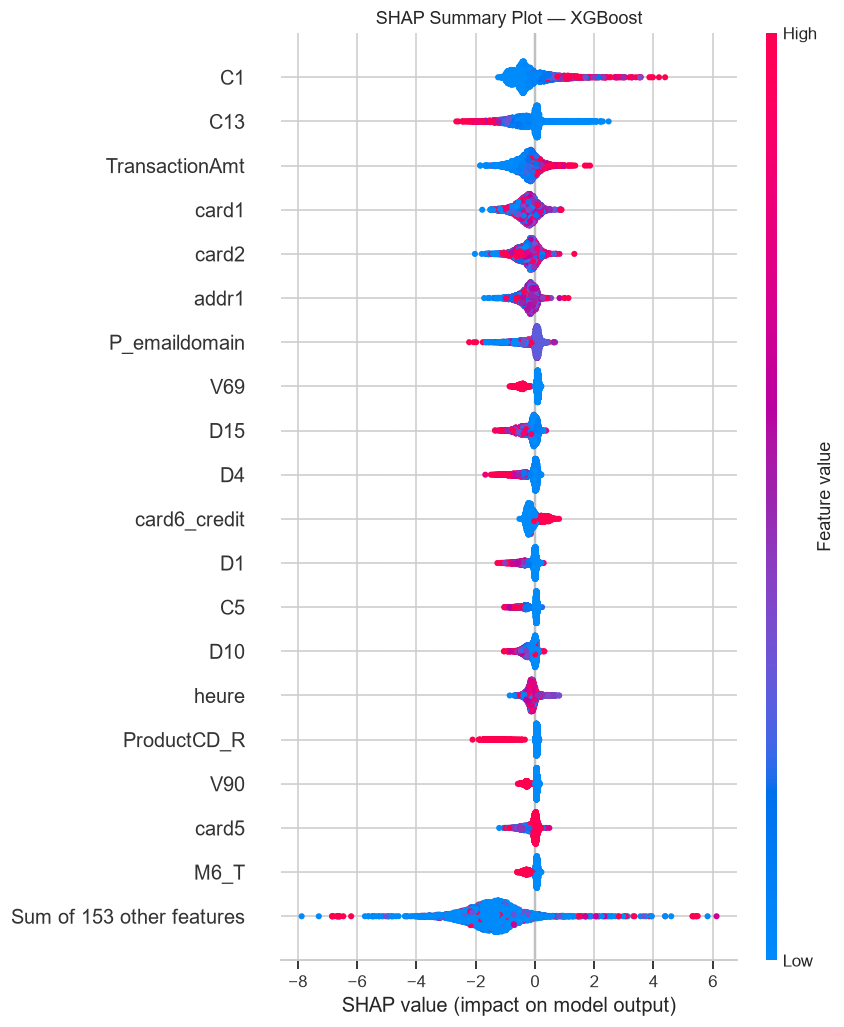

In [4]:
shap.plots.beeswarm(sv, max_display=20, show=False)
plt.title(f"SHAP Summary Plot — {nom_modele}")
plt.tight_layout()
plt.savefig(FIG / "05_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

### Interprétation — SHAP Summary Plot

**Comment lire.** Chaque point est une transaction. L'axe horizontal donne la contribution SHAP (à droite : pousse vers *fraude*, à gauche : vers *légitime*) ; la couleur indique la valeur de la variable (rouge = élevée, bleu = faible). Les variables sont triées de haut en bas par importance globale.

**Résultat.** On observe, pour chacune des variables du haut du graphique, si les valeurs élevées augmentent le risque (points rouges à droite) ou le diminuent, et si l'effet est régulier ou concentré sur quelques transactions (longue traîne de points isolés = effet très fort mais rare). C'est typiquement le cas des comptages `C*`, dont les valeurs extrêmes révèlent des cartes ou des adresses très actives.

**Points forts.** Une seule figure donne l'**importance globale, le sens et la dispersion** des effets ; elle révèle des relations non monotones et des effets de seuil que l'importance native ne montre pas.

**Limites.** Des points qui se superposent masquent la densité ; l'interprétation du sens suppose une variable continue (pour les variables binaires, rouge/bleu signifie seulement 1/0) ; les variables codées (`card1`, `addr1`, `P_emaildomain`) donnent un dégradé de couleurs sans signification métier.

## 10.4 SHAP Bar Plot

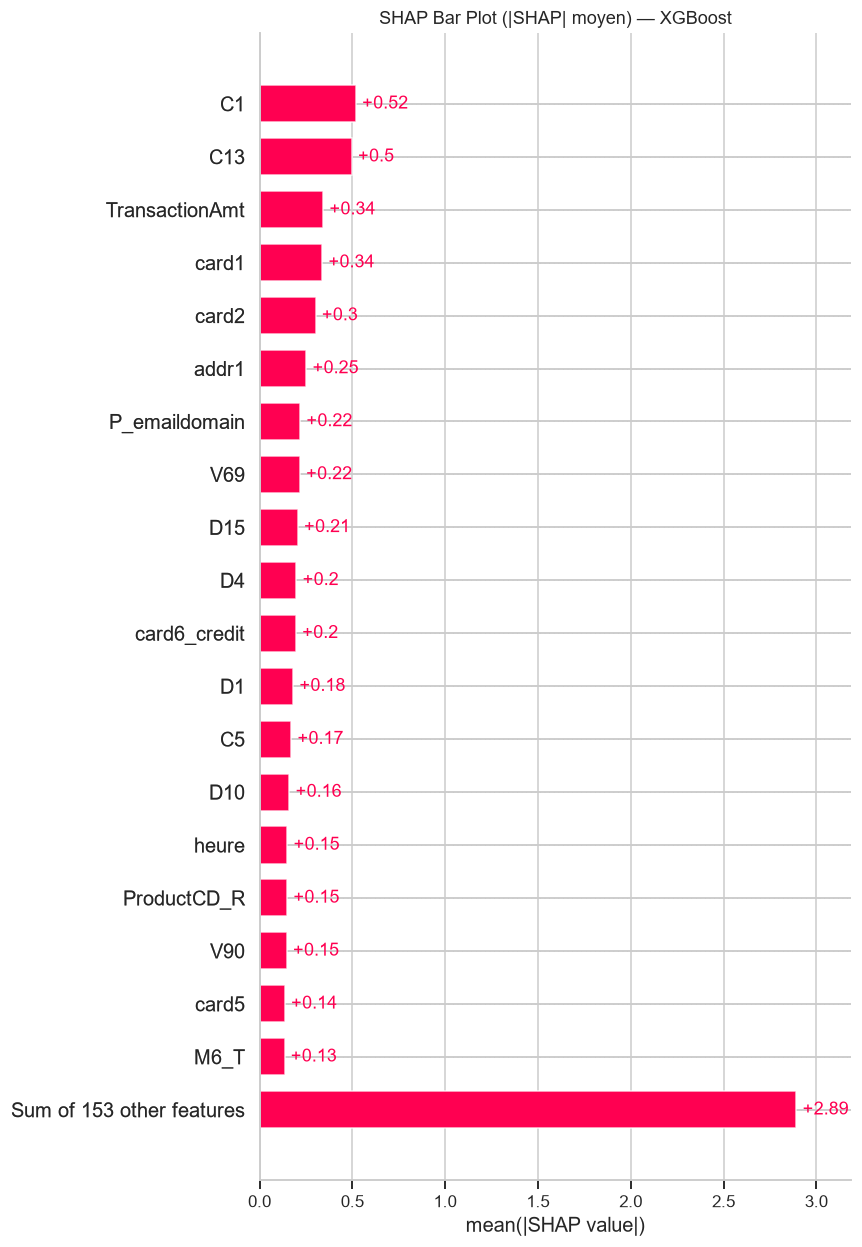

2 variables en commun parmi les 10 premières (SHAP et importance native) : ['C1', 'V69']


,|SHAP| moyen
C1,0.5191
C13,0.4970
TransactionAmt,0.3429
card1,0.3378
card2,0.3020
addr1,0.2520
P_emaildomain,0.2187
V69,0.2173
D15,0.2062
D4,0.1985


In [5]:
shap.plots.bar(sv, max_display=20, show=False)
plt.title(f"SHAP Bar Plot (|SHAP| moyen) — {nom_modele}")
plt.tight_layout()
plt.savefig(FIG / "05_shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

# Comparaison avec l'importance native : recouvrement des 10 premières variables
top_shap = pd.Series(np.abs(sv.values).mean(axis=0), index=X_shap.columns).sort_values(ascending=False)
recouvrement = set(top_shap.head(10).index) & set(top20.head(10).index)
print(f"{len(recouvrement)} variables en commun parmi les 10 premières (SHAP et importance native) :", sorted(recouvrement))
top_shap.head(10).to_frame("|SHAP| moyen")

### Interprétation — SHAP Bar Plot

**Résultat.** Le graphique classe les variables selon la contribution absolue moyenne à la prédiction : il quantifie *combien* chaque variable pèse, sans préciser le sens. Le recouvrement avec l'importance native (cellule précédente) mesure la cohérence entre deux méthodes indépendantes : un fort recouvrement renforce la confiance dans les conclusions.

**Points forts.** Lisible par un non-spécialiste ; échelle comparable d'une variable à l'autre ; classement plus fiable que l'importance par gain pour les variables à forte cardinalité.

**Limites.** Pas de sens (augmente/diminue le risque) ; une variable à effet rare mais très fort (comme certains comptages) peut sembler moins importante en moyenne qu'une variable à faible effet généralisé. On rapproche donc ce graphique du Summary Plot.

## 10.5 SHAP Waterfall Plot — explication d'une décision

Le diagramme en cascade part de la valeur de base (prédiction moyenne) et ajoute, variable par variable, les contributions jusqu'au score final de la transaction : il répond à « *pourquoi ce score ?* ».

Fraude détectée (vrai positif) | probabilité du modèle = 1.0000 (seuil = 0.5781)


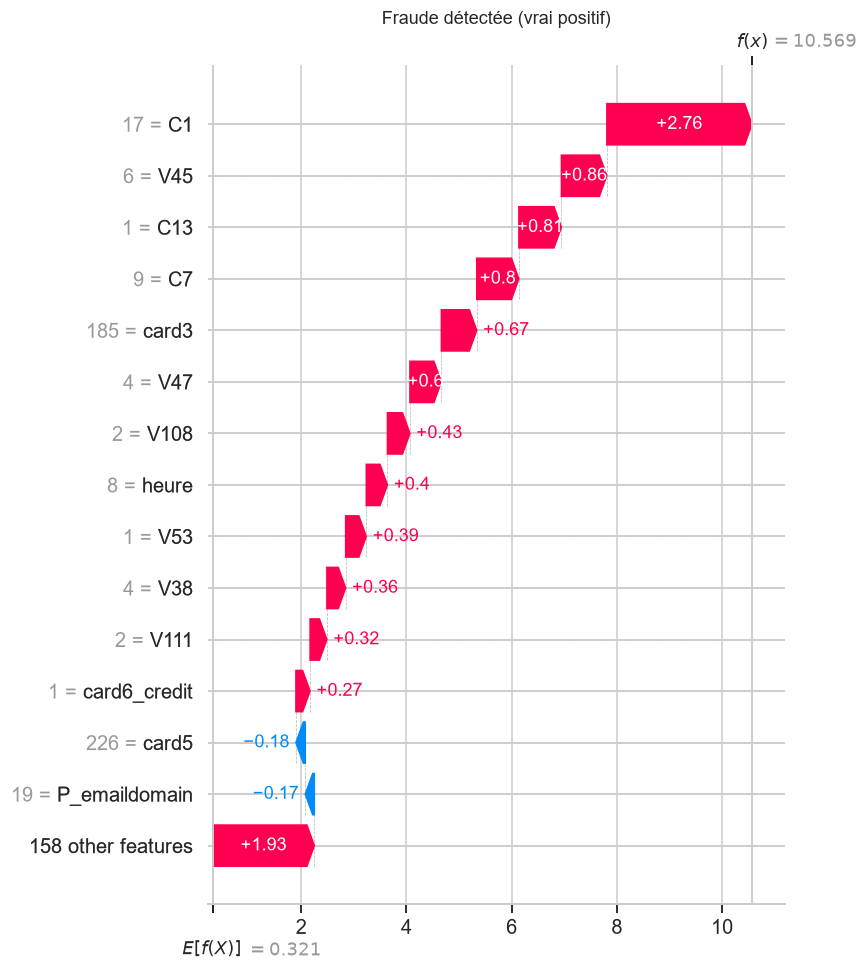

In [6]:
nom_cas = "Fraude détectée (vrai positif)"
pos = X_shap.index.get_loc(exemples[nom_cas])
print(f"{nom_cas} | probabilité du modèle = {proba_test[pos_tp]:.4f} (seuil = {seuil:.4f})")

shap.plots.waterfall(sv[pos], max_display=15, show=False)
plt.title(nom_cas)
plt.tight_layout()
plt.savefig(FIG / "05_shap_waterfall_vrai_positif.png", dpi=150, bbox_inches="tight")
plt.show()

### Interprétation — Waterfall d'une fraude détectée

**Résultat.** Les barres rouges (vers la droite) sont les variables qui ont fait monter le score vers *fraude*, les barres bleues celles qui l'ont fait baisser. La décision est la somme de plusieurs signaux ; l'écart entre `E[f(X)]` (valeur de base) et `f(x)` (score final) montre à quel point la transaction est jugée atypique. Ce type de cas s'explique en général par la combinaison de plusieurs signaux d'alerte (comptages anormaux, appareil ou produit à risque, absence ou présence d'identité) plutôt que par une variable unique.

**Points forts.** Explication **individuelle** et additive, utilisable pour justifier une alerte auprès d'un analyste ou d'un client ; les contributions s'additionnent exactement au score.

**Limites.** Valable pour **cette** transaction uniquement ; les contributions sont en log-odds, pas en probabilités ; l'effet d'une variable dépend des valeurs des autres (interactions), donc une même valeur peut contribuer différemment d'une transaction à l'autre.

Fraude manquée (faux négatif) | probabilité du modèle = 0.5752 (seuil = 0.5781)


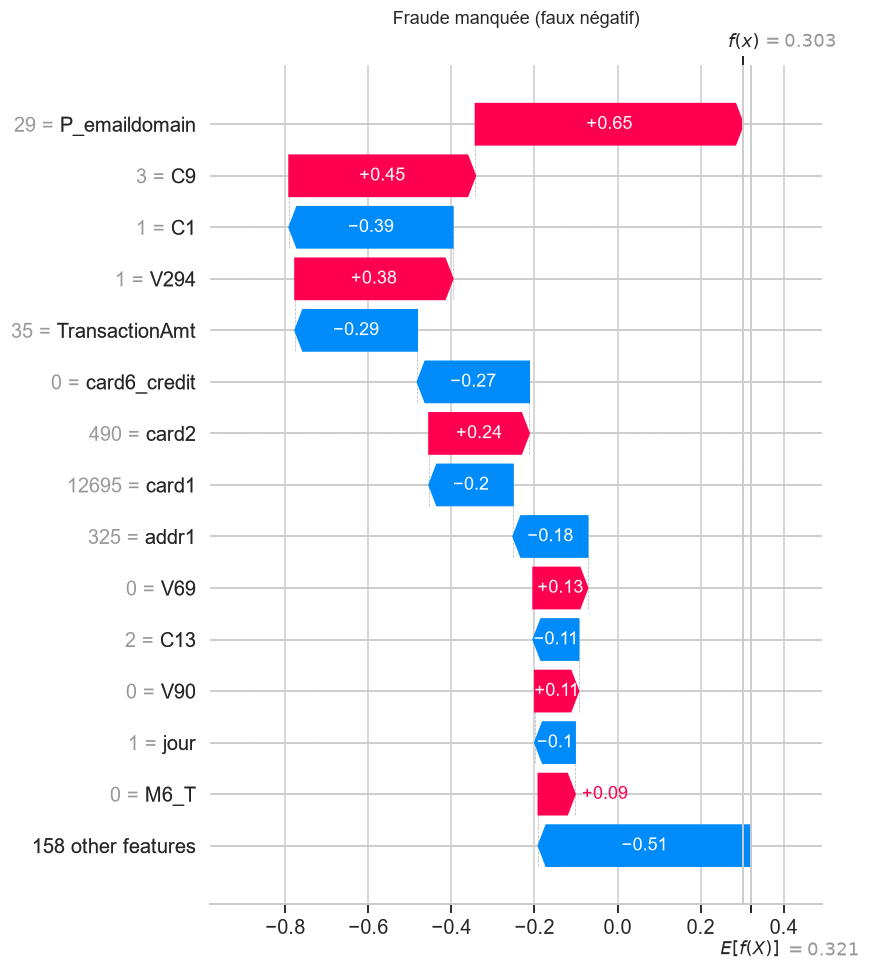

In [7]:
if pos_fn is not None:
    nom_cas = "Fraude manquée (faux négatif)"
    pos = X_shap.index.get_loc(exemples[nom_cas])
    print(f"{nom_cas} | probabilité du modèle = {proba_test[pos_fn]:.4f} (seuil = {seuil:.4f})")

    shap.plots.waterfall(sv[pos], max_display=15, show=False)
    plt.title(nom_cas)
    plt.tight_layout()
    plt.savefig(FIG / "05_shap_waterfall_faux_negatif.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Aucun faux négatif au seuil optimal sur le jeu de test.")

### Interprétation — Waterfall d'une fraude manquée

**Résultat.** Cette fraude n'a pas été signalée : les contributions qui poussent vers *fraude* (rouge) sont compensées par des contributions rassurantes (bleu), de sorte que le score reste en dessous du seuil. L'analyse des variables en bleu indique ce que cette fraude **imite** : un comportement qui ressemble à celui d'une transaction légitime (montant courant, produit courant, historique en apparence normal).

**Points forts.** Les faux négatifs sont le risque majeur du métier : comprendre pourquoi ils échappent au modèle oriente les actions (nouvelles variables, ajustement du seuil, règles métier complémentaires).

**Limites.** Un cas isolé ne suffit pas : pour généraliser, il faudrait comparer le profil SHAP moyen des faux négatifs à celui des vrais positifs. L'interprétation reste descriptive (le modèle, pas la réalité).

Transaction légitime (vrai négatif) | probabilité du modèle = 0.0000 (seuil = 0.5781)


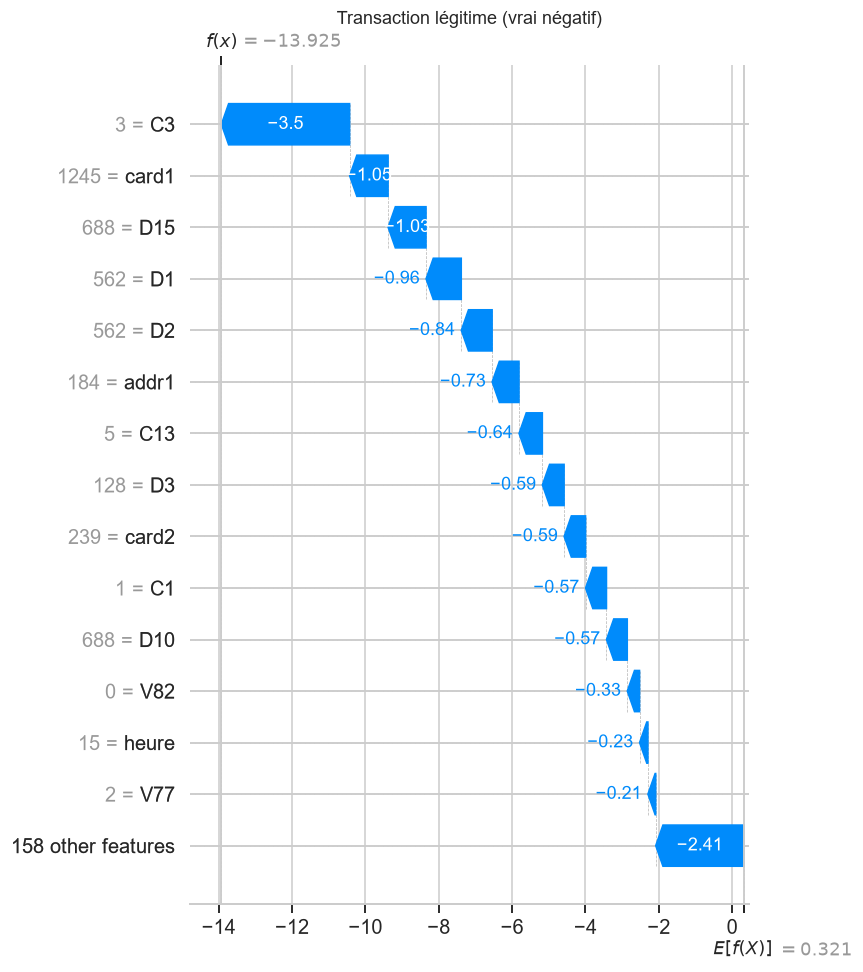

In [8]:
nom_cas = "Transaction légitime (vrai négatif)"
pos = X_shap.index.get_loc(exemples[nom_cas])
print(f"{nom_cas} | probabilité du modèle = {proba_test[pos_tn]:.4f} (seuil = {seuil:.4f})")

shap.plots.waterfall(sv[pos], max_display=15, show=False)
plt.title(nom_cas)
plt.tight_layout()
plt.savefig(FIG / "05_shap_waterfall_vrai_negatif.png", dpi=150, bbox_inches="tight")
plt.show()

### Interprétation — Waterfall d'une transaction légitime

**Résultat.** La cascade est dominée par des contributions vers la gauche (*légitime*) : le score final est très en dessous de la valeur de base. La comparaison avec le cas de fraude détectée met en évidence **les variables qui différencient** les deux profils.

**Points forts.** Sert de contrepoint pédagogique : un bon modèle doit s'expliquer aussi pour ce qu'il laisse passer.

**Limites.** Même réserve que pour le cas précédent : interprétation locale uniquement, en log-odds.

## 10.6 SHAP Force Plot

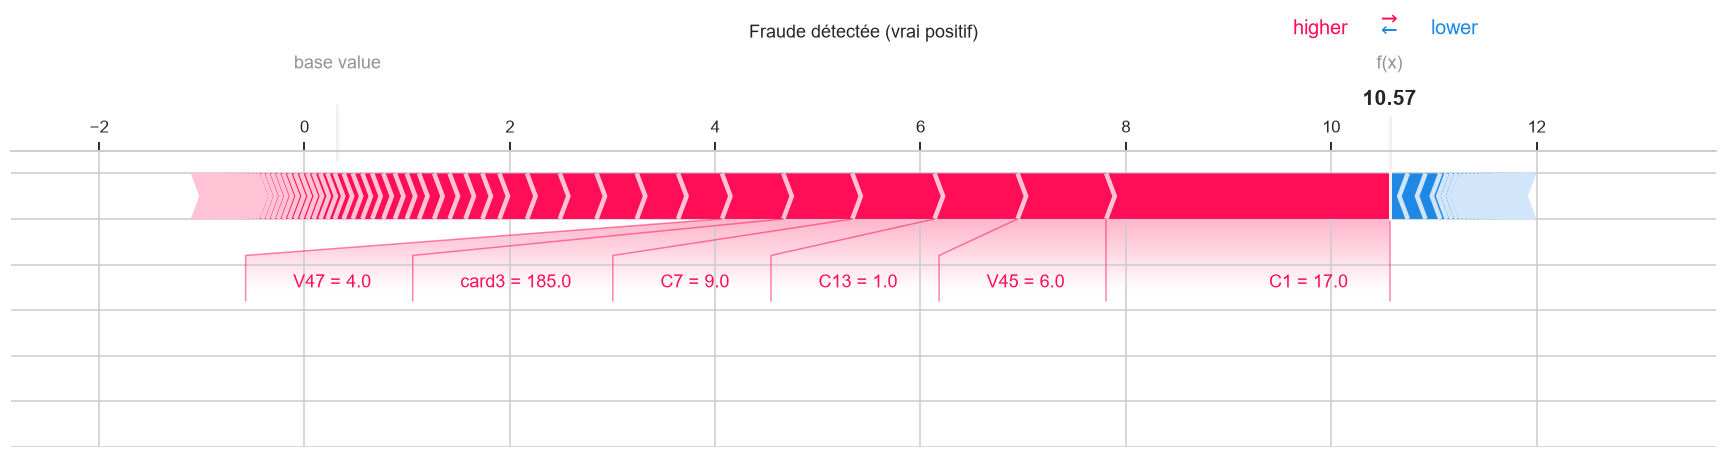

In [9]:
nom_cas = "Fraude détectée (vrai positif)"
pos = X_shap.index.get_loc(exemples[nom_cas])

# Version matplotlib (statique, exportable dans le rapport). Version interactive : shap.initjs(); shap.plots.force(sv[pos])
shap.force_plot(sv.base_values[pos], sv.values[pos], X_shap.iloc[pos].round(2), matplotlib=True, show=False, figsize=(20, 3.5))
plt.title(nom_cas, y=1.35)
plt.savefig(FIG / "05_shap_force_vrai_positif.png", dpi=150, bbox_inches="tight")
plt.show()

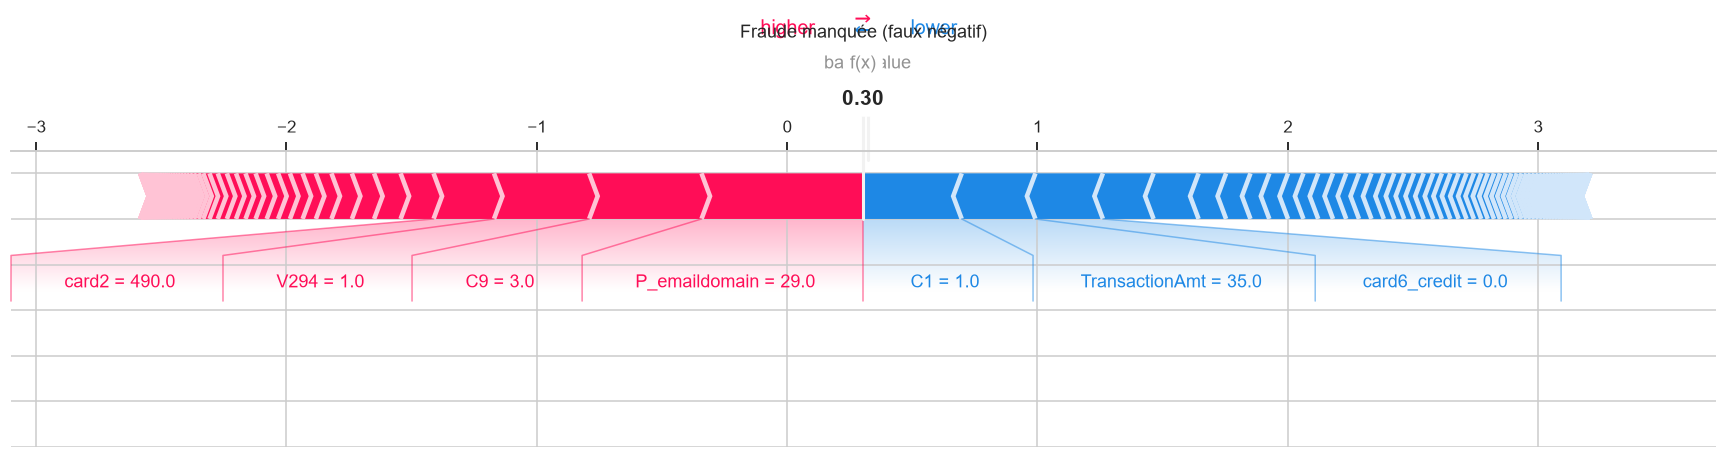

In [10]:
if pos_fn is not None:
    nom_cas = "Fraude manquée (faux négatif)"
    pos = X_shap.index.get_loc(exemples[nom_cas])
    shap.force_plot(sv.base_values[pos], sv.values[pos], X_shap.iloc[pos].round(2), matplotlib=True, show=False, figsize=(20, 3.5))
    plt.title(nom_cas, y=1.35)
    plt.savefig(FIG / "05_shap_force_faux_negatif.png", dpi=150, bbox_inches="tight")
    plt.show()

### Interprétation — SHAP Force Plot

**Comment lire.** Le graphique représente la même décomposition que le waterfall, sur une seule ligne : les variables en rouge poussent la prédiction **vers la droite** (*fraude*), celles en bleu **vers la gauche**, depuis la valeur de base jusqu'au score final `f(x)`. La largeur de chaque bloc est proportionnelle à la contribution ; la valeur de la variable est indiquée sous son nom.

**Résultat.** Pour la fraude détectée, les blocs rouges l'emportent largement et le score dépasse le seuil ; pour la fraude manquée, les deux forces se compensent presque et le score reste de peu sous le seuil. Cette lecture compacte convient à un tableau de bord d'analyste.

**Points forts.** Très compact, adapté à la communication ; la version interactive permet de survoler chaque variable.

**Limites.** Moins lisible que le waterfall quand beaucoup de variables contribuent (étiquettes qui se chevauchent) ; ne montre pas l'ordre d'importance chiffré ; la version statique n'affiche que les contributions les plus larges.

## 10.7 Synthèse du chapitre 10 et conséquences pour le métier

**Constats à reporter dans le mémoire (à compléter avec les variables affichées) :**
- Les variables dominantes (importance native et SHAP) sont cohérentes entre les deux méthodes ; ce recouvrement renforce la fiabilité du classement.
- Le Summary Plot indique le **sens** des effets : à documenter variable par variable pour les cinq à dix premières.
- Les waterfalls montrent que la décision résulte d'une **accumulation de signaux** : aucune variable ne suffit seule, ce qui rejoint l'analyse exploratoire (V de Cramer faibles).
- Le cas de faux négatif révèle les profils de fraude proches du comportement légitime, zone de risque résiduel.

**Recommandations métier :** renforcer la surveillance des profils présentant les signaux dominants, utiliser les explications SHAP pour justifier les alertes auprès des analystes, et revoir le seuil de décision selon le coût réel d'une fraude manquée.

**Limites générales :** SHAP décrit le comportement du modèle, non des causes ; les variables anonymisées (`C*`, `D*`, `V*`) limitent l'explication métier ; l'analyse porte sur un seul découpage aléatoire.

**Étape suivante** : le chapitre 11 (application Streamlit) intégrera la prédiction et l'explication SHAP locale d'une transaction.